# 09 — Clustering no supervisado (K-Means y HDBSCAN)

**Pregunta:** ¿los agarres aparecen solos, sin usar las etiquetas?

Se le dan al algoritmo las filas **sin decirle qué agarre es cada una**, se le pide que las separe en grupos
por parecido, y al final se compara si esos grupos coinciden con los agarres reales.

El clustering se hace **directamente sobre las columnas del dataset** (sin PCA).

### Cómo reutilizarlo con otro dataset (p. ej. canales fusionados)
Solo hay que cambiar **dos variables** en la primera celda: `DATA_PATH` y `FEATURE_COLS`.
Cada dataset guarda sus figuras y resultados en una carpeta propia.

| Sección | Contenido |
|---|---|
| 1 | Carga |
| 2 | K-Means con k = número de agarres: métricas, tabla y vista 2D |
| 3 | K-Means con otros valores de k |
| 4 | HDBSCAN: métricas, tabla y vista 2D |
| 5 | ¿Es mejor que el azar? (permutación) |
| 6 | Resumen y guardado |

In [1]:
# =====================================================================
# PARÁMETROS DEL DATASET — lo único que hay que cambiar para otro dataset
# =====================================================================
DATA_PATH = '../data/master/intact_bc_mean.csv'

_VARS = ['VAR_STD', 'Range', 'Energy', 'Peak_to_Peak', 'VAR', 'Max', 'MNF', 'SSC']
FEATURE_COLS = [f'Channel {ch}_{v}' for ch in range(1, 9) for v in _VARS]
# Ejemplo con fusión de canales:
# DATA_PATH = '../data/master/intact_bc_fused_mean.csv'
# FEATURE_COLS = ['VAR_STD', 'Range', 'Energy', 'Peak_to_Peak', 'VAR', 'Max', 'MNF', 'SSC']
# =====================================================================

In [2]:
# ---------------- Configuración (normalmente no se toca) ----------------
LABEL_COL, SUBJECT_COL, DB_COL = 'stimulus', 'subject', 'origin_db'
REST = 0
K_RANGE = range(2, 13)                # valores de k a probar en la sección 3
HDB_MIN_SIZES = [15, 20, 30, 40]      # tamaños mínimos de grupo a probar en HDBSCAN
N_PERM = 1000                         # repeticiones de la prueba de azar
RANDOM_STATE = 42
EMBED_2D = 'tsne'                     # cómo dibujar en 2D: 'tsne' | 'umap'
# -------------------------------------------------------------------------

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, HDBSCAN
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

N_FEATURES = len(FEATURE_COLS)
DATASET_TAG = f'{Path(DATA_PATH).stem}__{N_FEATURES}f'
SAVE_DIR = f'../figures/clustering/{DATASET_TAG}'
RESULTS_DIR = f'../results/clustering/{DATASET_TAG}'
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Dataset: {DATA_PATH} ({N_FEATURES} columnas)')
print(f'Figuras: {SAVE_DIR}\nResultados: {RESULTS_DIR}')


def style_ax(ax):
    ax.set_facecolor('#FFFFFF')
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#CCCCCC')
    ax.tick_params(colors='#444444', labelsize=8)


def savefig(fig, name):
    fig.savefig(f'{SAVE_DIR}/{name}.pdf', dpi=300, bbox_inches='tight')

Dataset: ../data/master/intact_bc_mean.csv (64 columnas)
Figuras: ../figures/clustering/intact_bc_mean__64f
Resultados: ../results/clustering/intact_bc_mean__64f


## 1. Carga

El dataset ya viene transformado y normalizado: solo se carga y se quita el reposo.
El sujeto se identifica con el ID compuesto `subject + origin_db`.

In [3]:
df = pd.read_csv(DATA_PATH)
missing = [c for c in [LABEL_COL, SUBJECT_COL, DB_COL] + FEATURE_COLS if c not in df.columns]
if missing:
    raise KeyError(f'Faltan columnas en el CSV ({len(missing)}): {missing[:10]}')

df = df[df[LABEL_COL] != REST].copy().reset_index(drop=True)
df['group'] = df[SUBJECT_COL].astype(str) + '_' + df[DB_COL].astype(str)

X = df[FEATURE_COLS].values.astype(float)
y = df[LABEL_COL].values
groups = df['group'].values

CLASSES = sorted(np.unique(y).tolist())
N_CLASSES = len(CLASSES)
CLASS_COLORS = dict(zip(CLASSES, sns.color_palette('tab10', N_CLASSES)))

print(f'Filas: {len(df)} | agarres ({N_CLASSES}): {CLASSES} | sujetos: {len(np.unique(groups))}')

Filas: 609 | agarres (7): [22, 25, 27, 30, 31, 37, 40] | sujetos: 87


In [4]:
# ---------- Funciones de evaluación y de gráficas ----------

def clusters_per_subject(labels):
    # En cuántos grupos distintos caen los agarres de cada sujeto (media).
    # ≈ número de agarres → bien (agrupa agarres). ≈ 1 → agrupa personas.
    s = pd.DataFrame({'g': groups, 'c': labels})
    s = s[s['c'] >= 0]
    return s.groupby('g')['c'].nunique().mean()


def evaluate(labels):
    return {
        'ARI_agarre': adjusted_rand_score(y, labels),
        'NMI_agarre': normalized_mutual_info_score(y, labels),
        'ARI_sujeto': adjusted_rand_score(groups, labels),
        'grupos_por_sujeto': clusters_per_subject(labels),
    }


def plot_contingency(labels, title, fname):
    # Filas = grupos encontrados; columnas = agarres reales; número = cuántas filas
    ct = pd.crosstab(pd.Series(labels, name='Grupo encontrado'), pd.Series(y, name='Agarre real'))
    ct = ct.reindex(columns=CLASSES, fill_value=0)
    ct_norm = ct.div(ct.sum(axis=0), axis=1)
    fig, ax = plt.subplots(figsize=(1.1 * N_CLASSES + 2, 0.55 * len(ct) + 1.8), dpi=300)
    fig.patch.set_facecolor('#F7F9FC')
    sns.heatmap(ct_norm, annot=ct.values, fmt='d', cmap='Blues', vmin=0, vmax=1,
                linewidths=0.5, linecolor='#FFFFFF',
                cbar_kws={'label': 'Proporción del agarre'}, ax=ax)
    ax.set_title(title, fontweight='bold', fontsize=10)
    plt.tight_layout()
    savefig(fig, fname)
    plt.show()


# Coordenadas 2D: se calculan una sola vez y se usan en todas las vistas 2D
if EMBED_2D == 'umap':
    import umap
    E2D = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                    random_state=RANDOM_STATE).fit_transform(X)
    AXIS = 'UMAP'
else:
    E2D = TSNE(n_components=2, perplexity=30, init='pca',
               random_state=RANDOM_STATE).fit_transform(X)
    AXIS = 't-SNE'


def plot_clusters_2d(labels, title, fname):
    # Izquierda: grupos encontrados. Derecha: agarres reales. Mismas coordenadas.
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), dpi=300, sharex=True, sharey=True)
    fig.patch.set_facecolor('#F7F9FC')

    ax = axes[0]
    found = [c for c in sorted(set(labels)) if c >= 0]
    pal = sns.color_palette('Set2', max(1, len(found)))
    if (labels < 0).any():
        m = labels < 0
        ax.scatter(E2D[m, 0], E2D[m, 1], s=14, color='#BDBDBD', alpha=0.5, label='Ruido (−1)')
    for c, col in zip(found, pal):
        m = labels == c
        ax.scatter(E2D[m, 0], E2D[m, 1], s=28, color=col, alpha=0.85,
                   edgecolor='white', linewidth=0.4, label=f'Grupo {c}')
        ax.text(np.median(E2D[m, 0]), np.median(E2D[m, 1]), str(c), fontsize=11,
                fontweight='bold', ha='center', va='center',
                bbox=dict(boxstyle='circle,pad=0.25', fc='white', ec=col, lw=1.5))
    ax.set_title('Grupos encontrados', fontweight='bold')

    ax = axes[1]
    for cls in CLASSES:
        m = y == cls
        ax.scatter(E2D[m, 0], E2D[m, 1], s=28, color=CLASS_COLORS[cls], alpha=0.85,
                   edgecolor='white', linewidth=0.4, label=f'Agarre {cls}')
    ax.set_title('Agarres reales', fontweight='bold')

    for ax in axes:
        style_ax(ax)
        ax.set_xlabel(f'{AXIS} 1', fontweight='bold')
        ax.legend(fontsize=7, loc='best', frameon=True)
    axes[0].set_ylabel(f'{AXIS} 2', fontweight='bold')
    fig.suptitle(title, fontweight='bold', fontsize=11)
    plt.tight_layout()
    savefig(fig, fname)
    plt.show()

## 2. K-Means con k = número de agarres

Se le pide a K-Means que forme tantos grupos como agarres hay.

**Qué mirar:**
- **ARI / NMI agarre:** cuánto coinciden los grupos con los agarres (0 = como al azar, 1 = perfecto).
- **ARI sujeto:** control. Si es mayor que el de agarre, los grupos separan personas, no agarres.
- **Grupos por sujeto:** en cuántos grupos distintos caen los agarres de una misma persona. Cerca del
  número de agarres = bien; cerca de 1 = agrupa por persona.
- **Tabla:** filas = grupos encontrados, columnas = agarres reales. Muestra qué agarres quedan juntos.
- **Vista 2D:** izquierda coloreada por grupo, derecha por agarre real, con las mismas coordenadas.
  La 2D es solo para ver; las conclusiones salen del ARI y de la tabla.

,K-Means
k,7.000
silhouette,0.116
ARI_agarre,0.160
NMI_agarre,0.237
ARI_sujeto,-0.006
grupos_por_sujeto,5.149


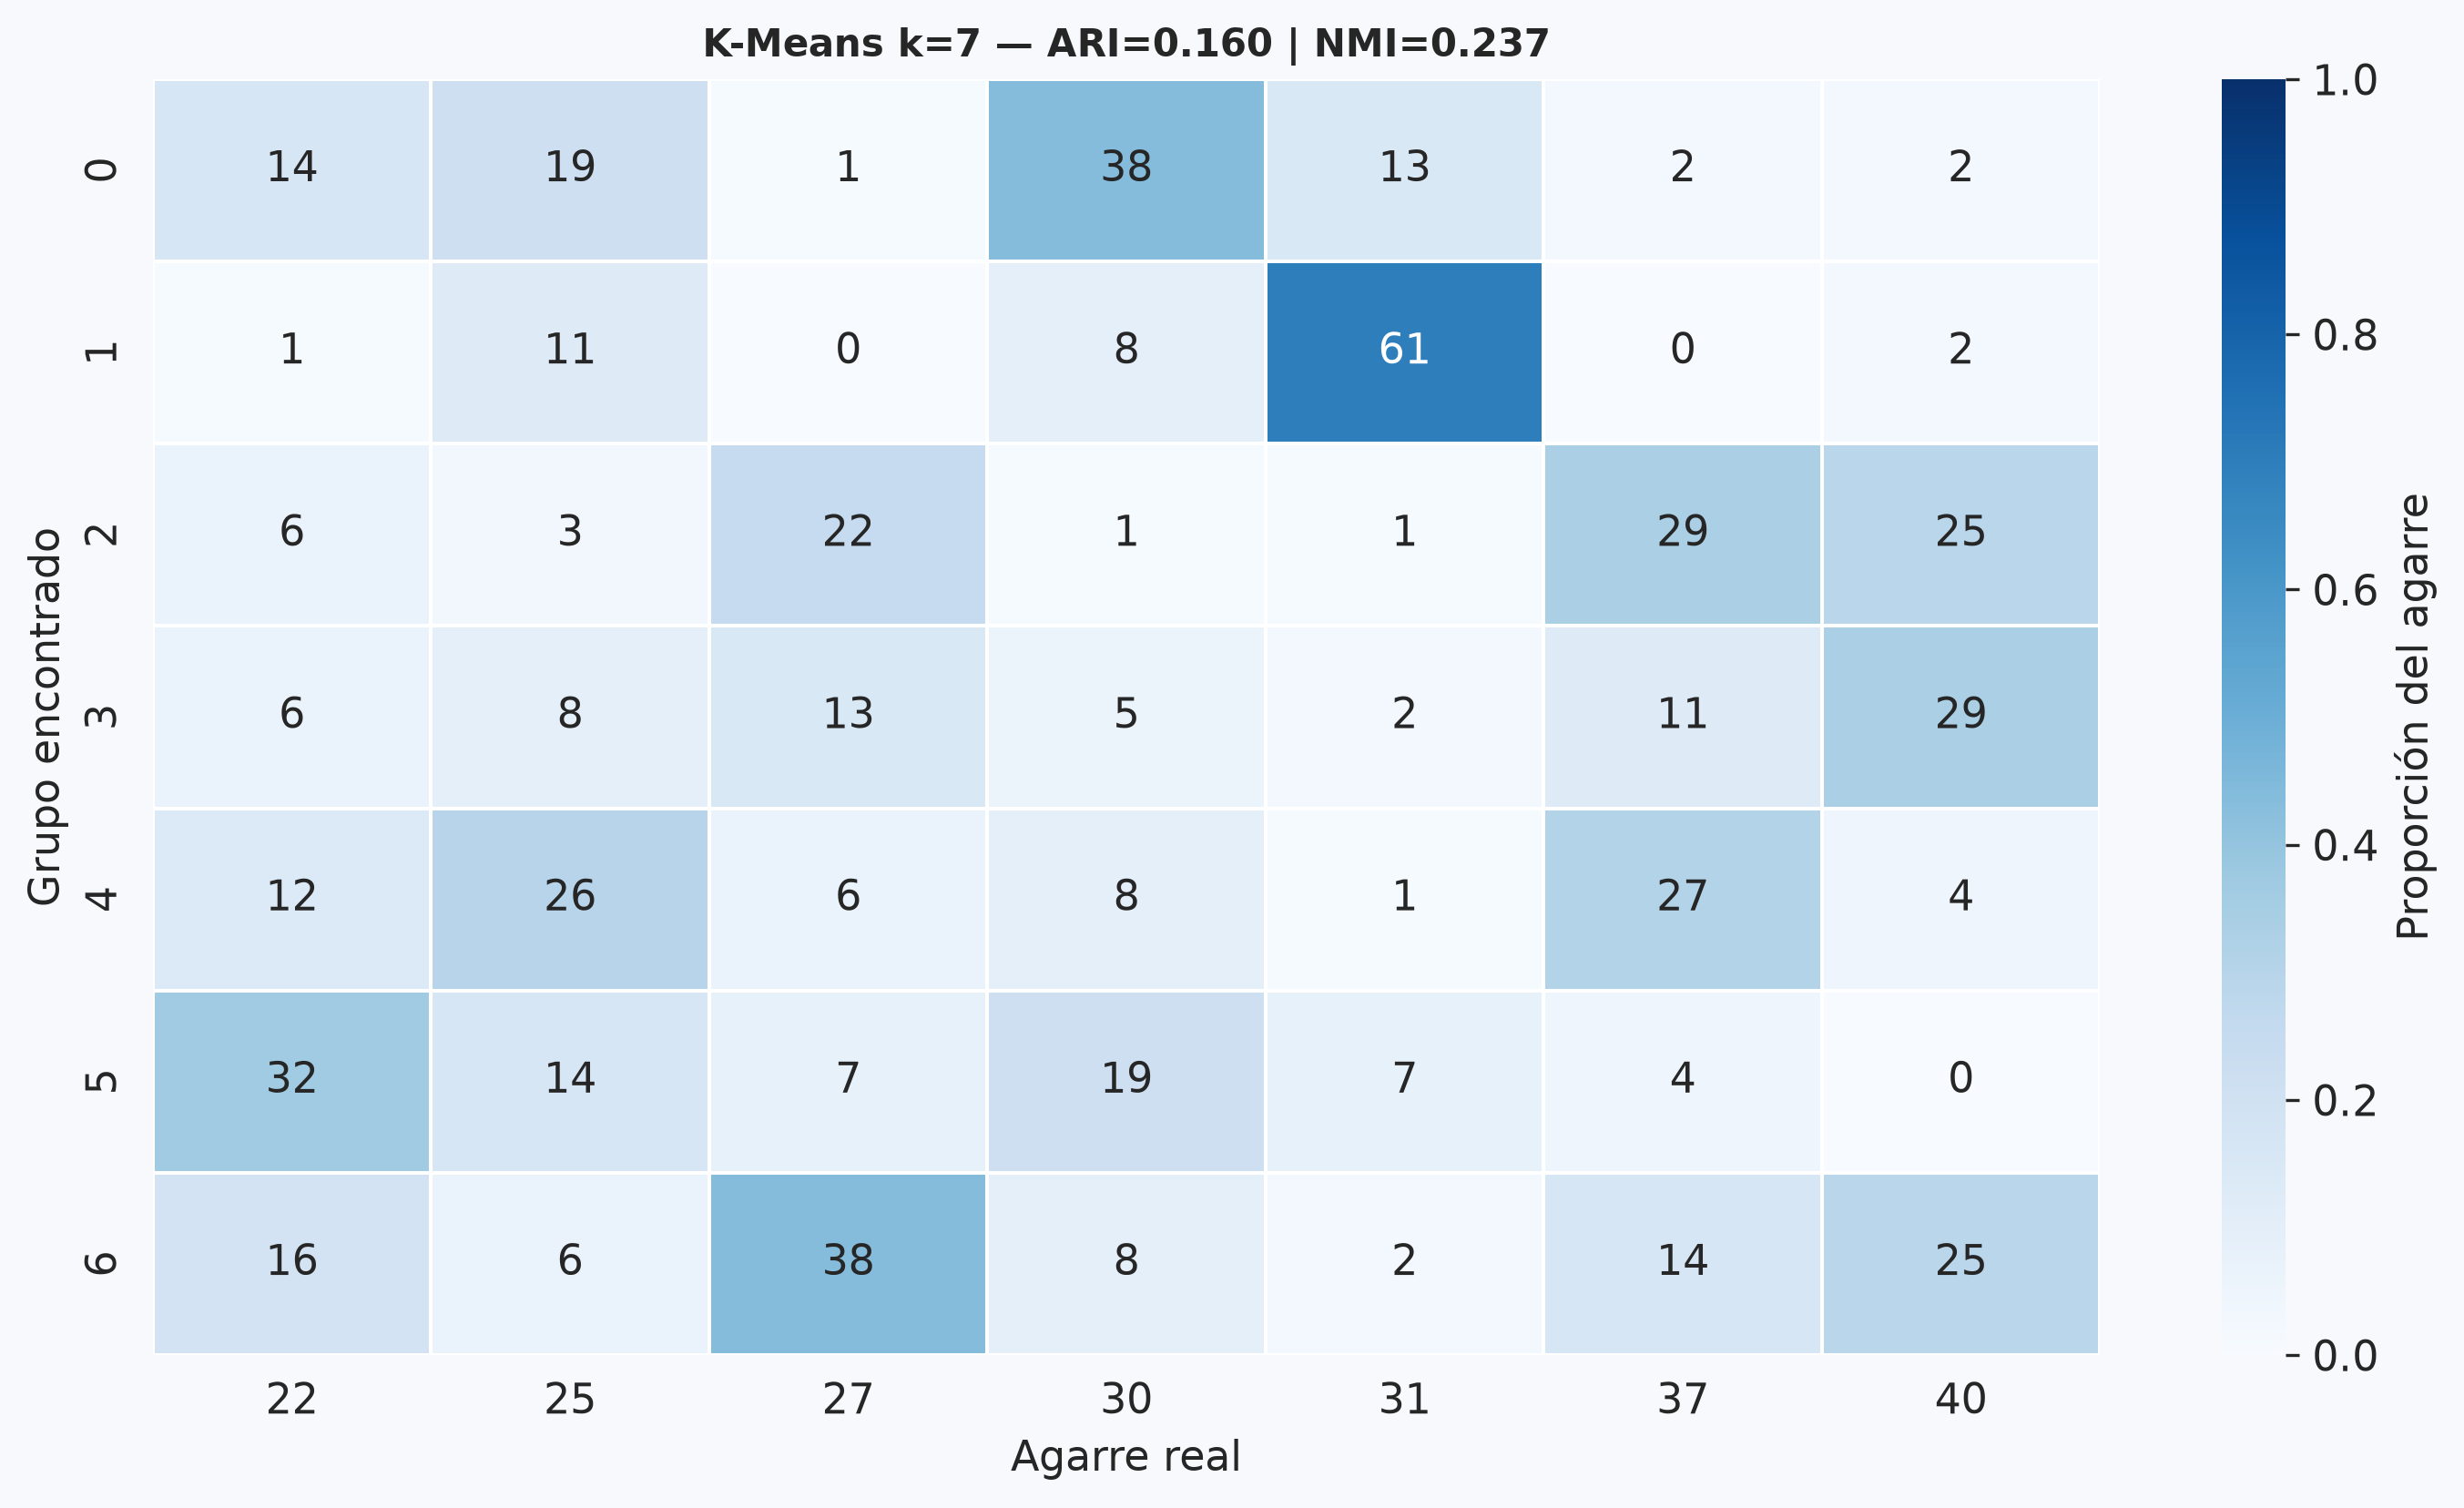

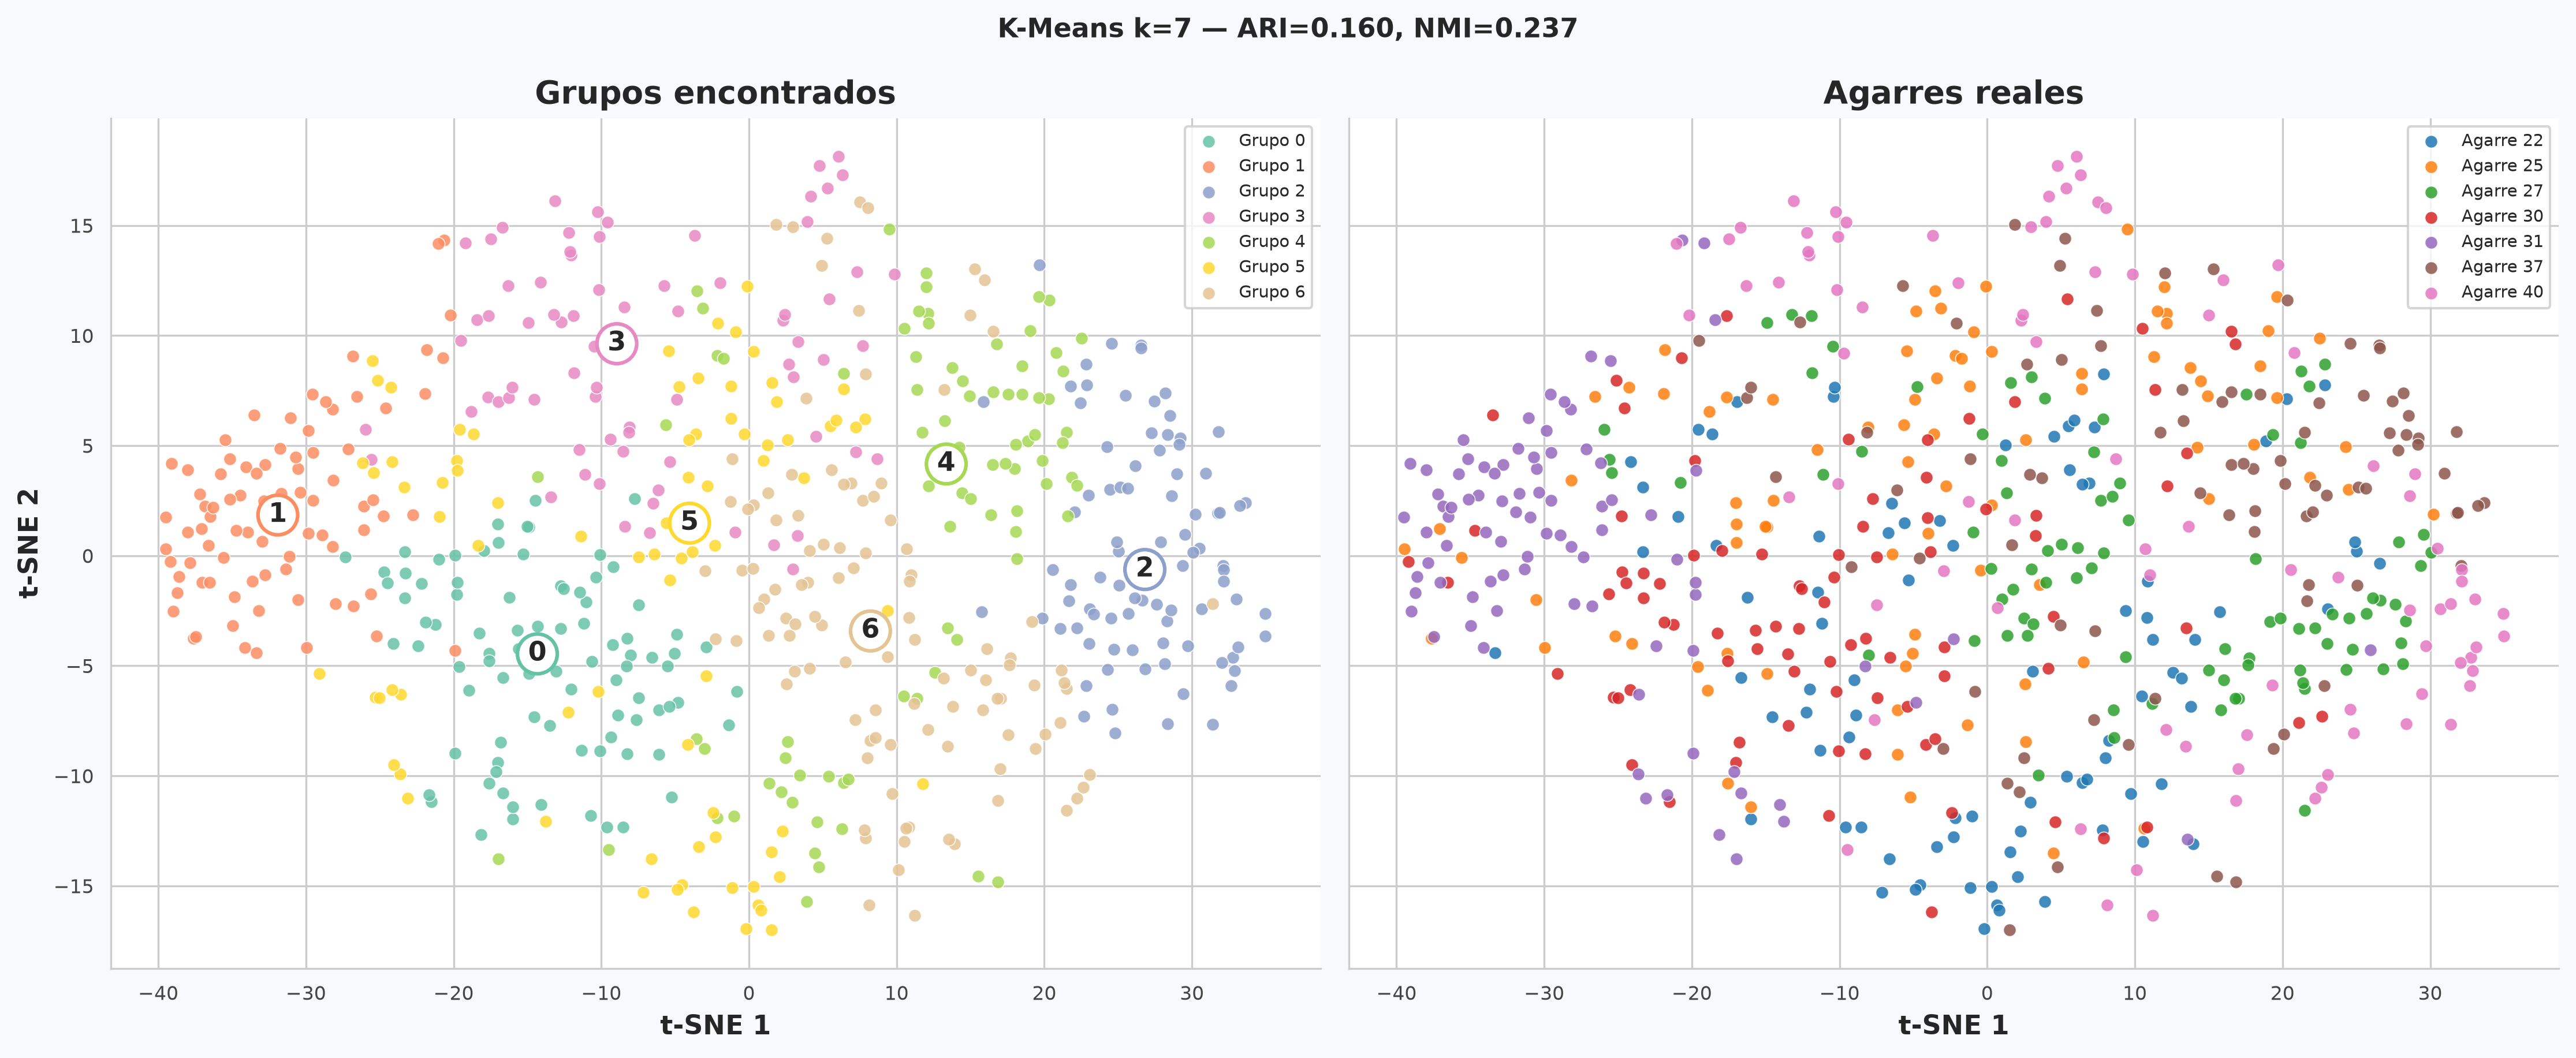

In [5]:
km = KMeans(n_clusters=N_CLASSES, n_init=50, random_state=RANDOM_STATE).fit(X)
km_labels = km.labels_
km_res = {'k': N_CLASSES, 'silhouette': silhouette_score(X, km_labels), **evaluate(km_labels)}
display(pd.Series(km_res).round(3).to_frame('K-Means'))

plot_contingency(km_labels,
                 f'K-Means k={N_CLASSES} — ARI={km_res["ARI_agarre"]:.3f} | NMI={km_res["NMI_agarre"]:.3f}',
                 'kmeans_tabla')
plot_clusters_2d(km_labels,
                 f'K-Means k={N_CLASSES} — ARI={km_res["ARI_agarre"]:.3f}, NMI={km_res["NMI_agarre"]:.3f}',
                 'kmeans_2d')

## 3. K-Means con otros valores de k

Se repite K-Means con distintos números de grupos.
- **Silhouette** (izquierda): qué tan bien separados quedan los grupos. El k con el valor más alto es el
  número de grupos que "prefieren" los datos. Si es menor que el número de agarres, algunos agarres forman
  familias.
- **ARI / NMI** (derecha): coincidencia con los agarres para cada k.

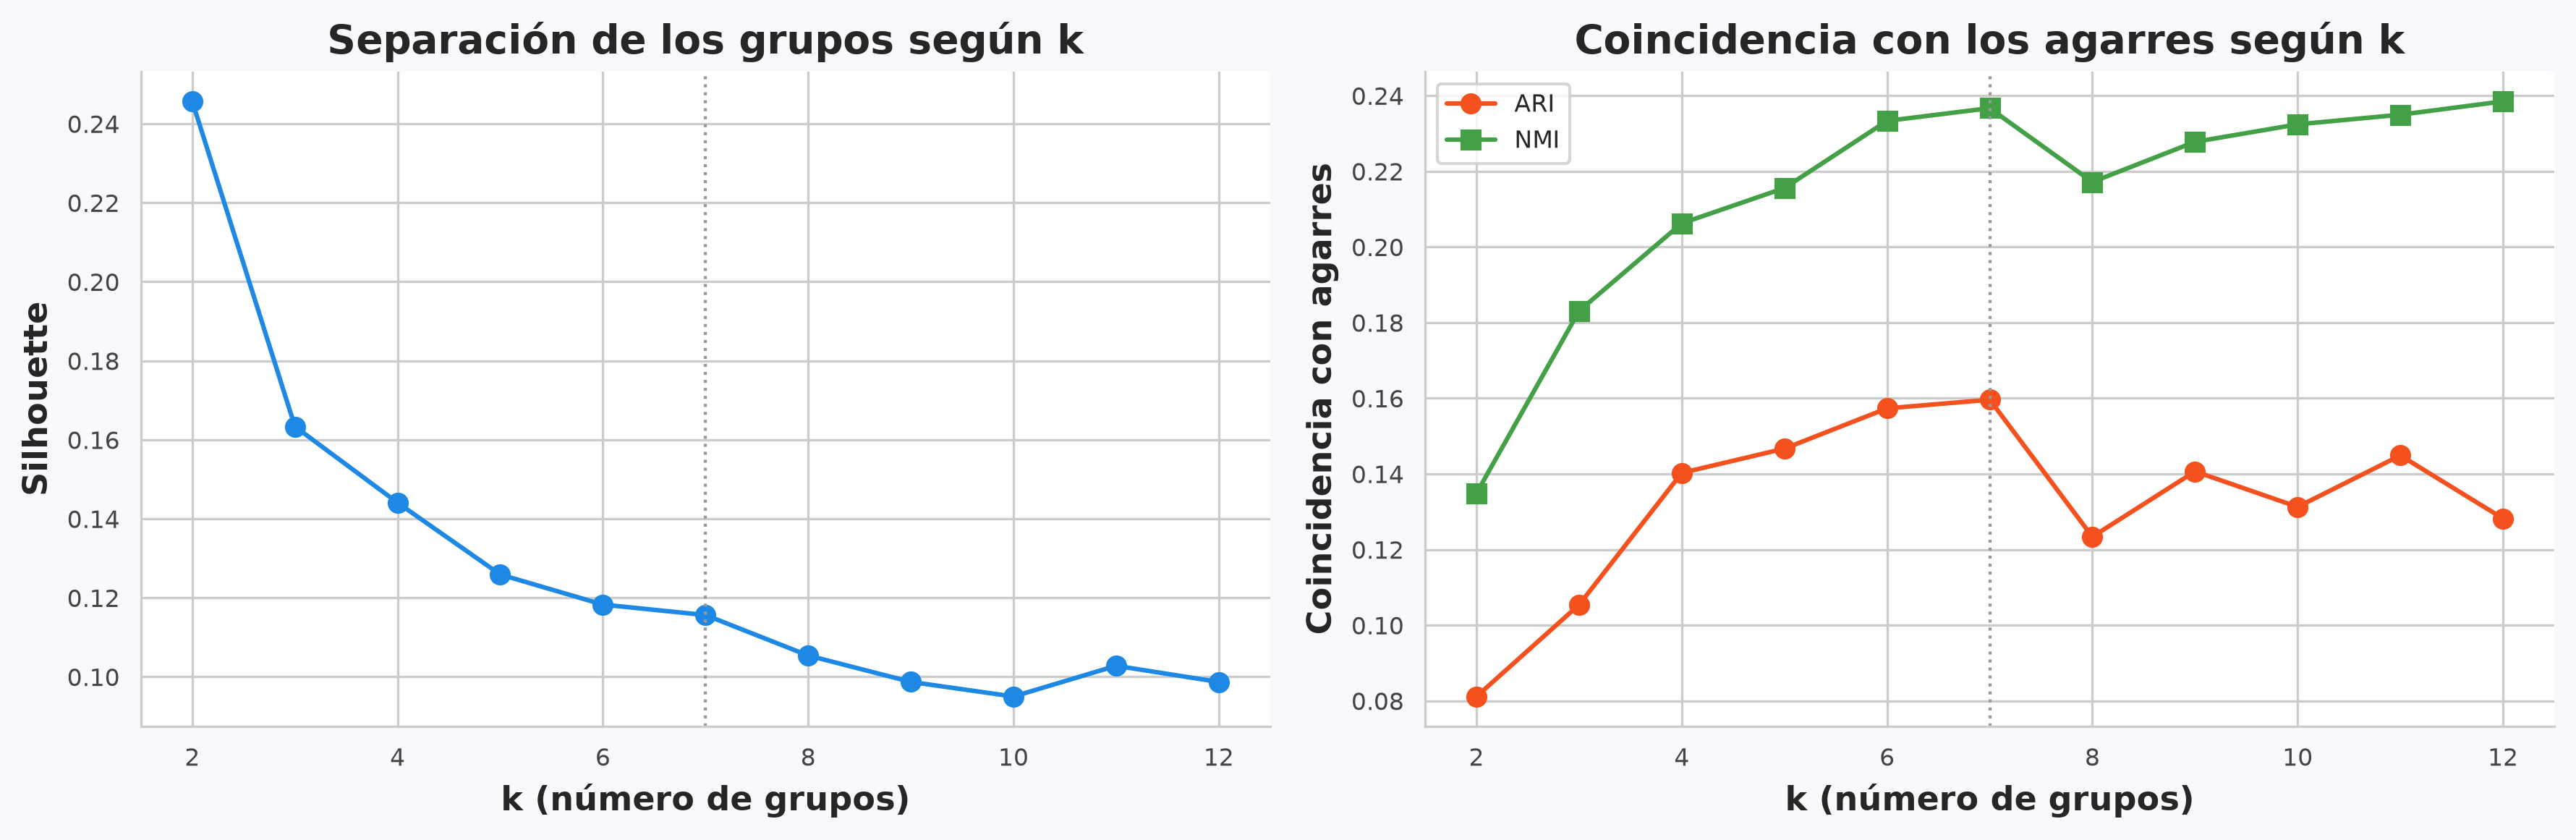

k con mejor separación (silhouette): 2  |  número de agarres: 7


In [6]:
sweep = []
for k in K_RANGE:
    lab = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
    sweep.append({'k': k, 'silhouette': silhouette_score(X, lab),
                  'ARI_agarre': adjusted_rand_score(y, lab),
                  'NMI_agarre': normalized_mutual_info_score(y, lab)})
sweep_df = pd.DataFrame(sweep)
best_k = int(sweep_df.loc[sweep_df['silhouette'].idxmax(), 'k'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=300)
fig.patch.set_facecolor('#F7F9FC')
axes[0].plot(sweep_df['k'], sweep_df['silhouette'], marker='o', color='#1E88E5')
axes[0].set_ylabel('Silhouette', fontweight='bold')
axes[0].set_title('Separación de los grupos según k', fontweight='bold')
axes[1].plot(sweep_df['k'], sweep_df['ARI_agarre'], marker='o', color='#F4511E', label='ARI')
axes[1].plot(sweep_df['k'], sweep_df['NMI_agarre'], marker='s', color='#43A047', label='NMI')
axes[1].set_ylabel('Coincidencia con agarres', fontweight='bold')
axes[1].set_title('Coincidencia con los agarres según k', fontweight='bold')
axes[1].legend(fontsize=8)
for ax in axes:
    style_ax(ax)
    ax.axvline(N_CLASSES, color='#999999', linestyle=':', linewidth=1)
    ax.set_xlabel('k (número de grupos)', fontweight='bold')
plt.tight_layout()
savefig(fig, 'kmeans_barrido_k')
plt.show()
print(f'k con mejor separación (silhouette): {best_k}  |  número de agarres: {N_CLASSES}')

## 4. HDBSCAN

A diferencia de K-Means, **HDBSCAN decide solo cuántos grupos hay**. Las filas que no encajan en ningún
grupo las marca como **ruido (−1)**, en gris en la vista 2D.

`min_cluster_size` es el tamaño mínimo para que algo cuente como grupo; se prueban varios valores.
Un ARI alto con mucho ruido no es un buen resultado: hay que mirar ambos.

In [7]:
hdb_rows, hdb_labels = [], {}
for mcs in HDB_MIN_SIZES:
    lab = HDBSCAN(min_cluster_size=mcs).fit_predict(X)
    hdb_labels[mcs] = lab
    hdb_rows.append({'min_cluster_size': mcs,
                     'n_grupos': len(set(lab[lab >= 0])),
                     '%_ruido': 100 * (lab < 0).mean(),
                     **evaluate(lab)})
hdb_df = pd.DataFrame(hdb_rows).set_index('min_cluster_size')
display(hdb_df.round(3))

valid = hdb_df[hdb_df['n_grupos'] > 1]
if len(valid):
    best_mcs = valid['ARI_agarre'].idxmax()
    r = hdb_df.loc[best_mcs]
    title = (f'HDBSCAN (min_cluster_size={best_mcs}) — {int(r.n_grupos)} grupos, '
             f'{r["%_ruido"]:.0f}% ruido, ARI={r.ARI_agarre:.3f}')
    plot_contingency(hdb_labels[best_mcs], title, 'hdbscan_tabla')
    plot_clusters_2d(hdb_labels[best_mcs], title, 'hdbscan_2d')
else:
    best_mcs = None
    print('HDBSCAN no encontró más de un grupo con ningún min_cluster_size '
          '(todo es un solo grupo o ruido). Esto también es un resultado: no hay regiones densas separadas.')

,n_grupos,%_ruido,ARI_agarre,NMI_agarre,ARI_sujeto,grupos_por_sujeto
min_cluster_size,,,,,,
15,0,100.0,0.0,0.0,0.0,NaN
20,0,100.0,0.0,0.0,0.0,NaN
30,0,100.0,0.0,0.0,0.0,NaN
40,0,100.0,0.0,0.0,0.0,NaN


HDBSCAN no encontró más de un grupo con ningún min_cluster_size (todo es un solo grupo o ruido). Esto también es un resultado: no hay regiones densas separadas.


## 5. ¿Es mejor que el azar?

Se mezclan al azar las etiquetas de agarre `N_PERM` veces y se calcula el ARI de K-Means cada vez.
Eso muestra qué ARI saldría por pura suerte. Si el ARI real queda muy a la derecha del histograma
(p-valor bajo), la coincidencia no es casualidad.

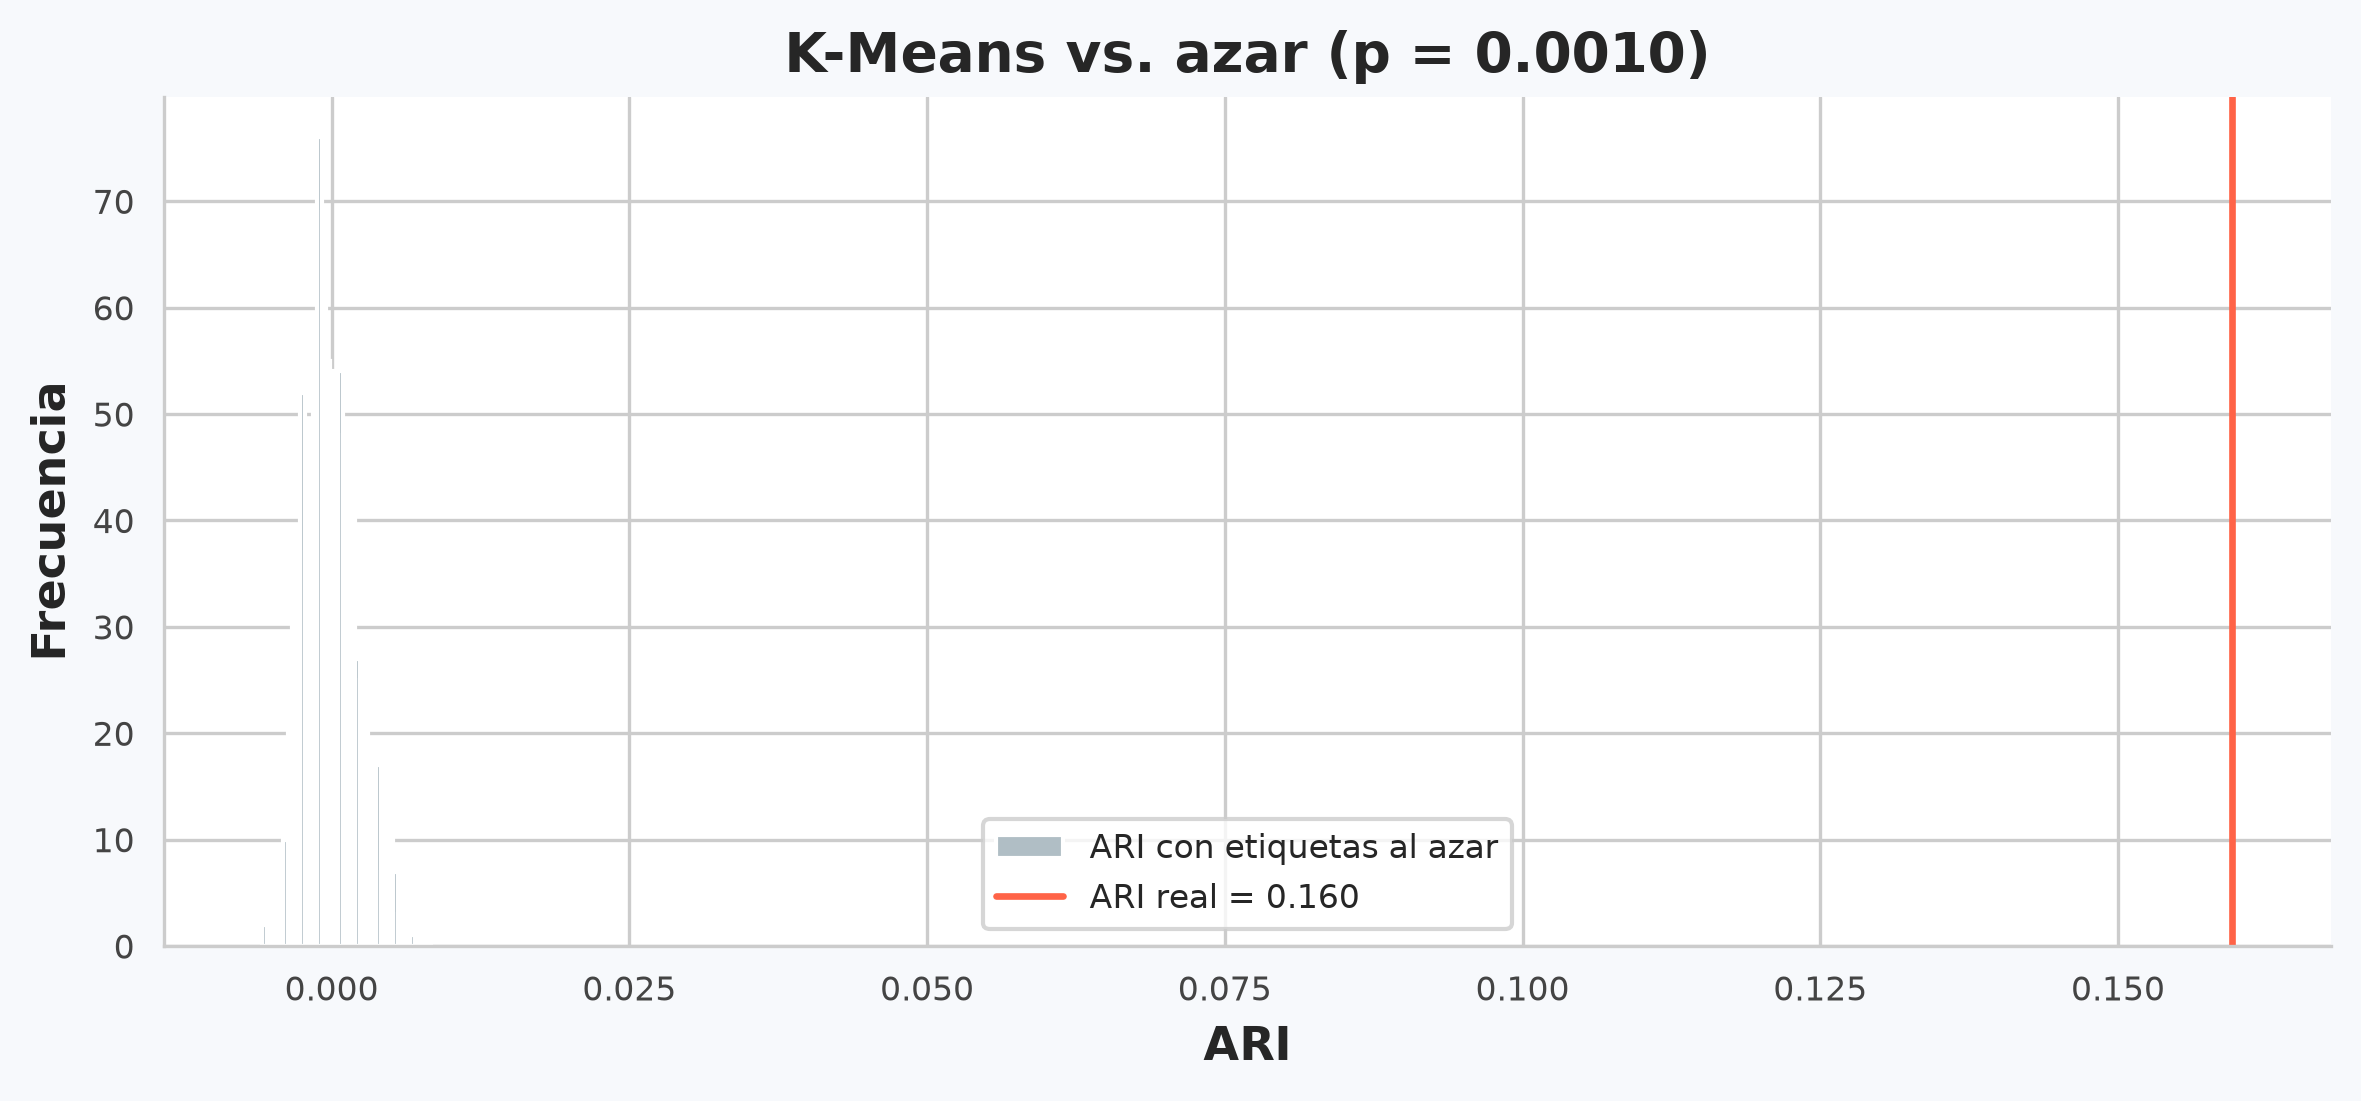

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
obs = km_res['ARI_agarre']
null = np.array([adjusted_rand_score(rng.permutation(y), km_labels) for _ in range(N_PERM)])
p_val = (np.sum(null >= obs) + 1) / (N_PERM + 1)

fig, ax = plt.subplots(figsize=(8, 3.8), dpi=300)
fig.patch.set_facecolor('#F7F9FC')
style_ax(ax)
ax.hist(null, bins=40, color='#B0BEC5', edgecolor='white', label='ARI con etiquetas al azar')
ax.axvline(obs, color='tomato', linewidth=1.6, label=f'ARI real = {obs:.3f}')
ax.set_xlabel('ARI', fontweight='bold')
ax.set_ylabel('Frecuencia', fontweight='bold')
ax.set_title(f'K-Means vs. azar (p = {p_val:.4f})', fontweight='bold')
ax.legend(fontsize=8)
plt.tight_layout()
savefig(fig, 'kmeans_vs_azar')
plt.show()

## 6. Resumen y guardado

Se guarda un `resumen.csv` por dataset. Para comparar con la fusión de canales, se ejecuta este notebook
con el otro dataset y se comparan los dos `resumen.csv`.

In [ ]:
assign = df[[SUBJECT_COL, DB_COL, 'group', LABEL_COL]].copy()
assign['kmeans'] = km_labels
if best_mcs is not None:
    assign['hdbscan'] = hdb_labels[best_mcs]
assign.to_csv(f'{RESULTS_DIR}/asignaciones.csv', index=False)
sweep_df.to_csv(f'{RESULTS_DIR}/kmeans_barrido_k.csv', index=False)
hdb_df.to_csv(f'{RESULTS_DIR}/hdbscan_metricas.csv')

resumen = {
    'dataset': DATASET_TAG,
    'n_columnas': N_FEATURES,
    'kmeans_ARI_agarre': km_res['ARI_agarre'],
    'kmeans_NMI_agarre': km_res['NMI_agarre'],
    'kmeans_ARI_sujeto': km_res['ARI_sujeto'],
    'kmeans_grupos_por_sujeto': km_res['grupos_por_sujeto'],
    'kmeans_p_azar': p_val,
    'k_mejor_separacion': best_k,
    'hdbscan_n_grupos': None if best_mcs is None else int(hdb_df.loc[best_mcs, 'n_grupos']),
    'hdbscan_pct_ruido': None if best_mcs is None else hdb_df.loc[best_mcs, '%_ruido'],
    'hdbscan_ARI_agarre': None if best_mcs is None else hdb_df.loc[best_mcs, 'ARI_agarre'],
}
pd.DataFrame([resumen]).to_csv(f'{RESULTS_DIR}/resumen.csv', index=False)
display(pd.Series(resumen).to_frame('valor'))

## 7. Interpretación

*(Completar con los resultados.)*

- **¿Se forman los agarres solos?** → ARI/NMI de K-Means y p-valor frente al azar.
- **¿Qué agarres se mezclan?** → tabla de K-Means; comparar con los pares más confundidos de la LDA.
- **¿Se agrupa por persona?** → ARI sujeto y grupos por sujeto.
- **¿Cuántos grupos sugieren los datos?** → k con mejor separación y resultado de HDBSCAN.